We can use this notebook if that is more convenient for others.

Select venv as the kernel after setup

,sample_size,p_baseline,type1_z,type1_lrt
0,30,0.005,0.0000,0.0005
1,50,0.005,0.0001,0.0032
2,100,0.005,0.0020,0.0177
3,250,0.005,0.0220,0.0772
4,500,0.005,0.0476,0.0954
5,1000,0.005,0.0425,0.0700
6,5000,0.005,0.0492,0.0504
7,20000,0.005,0.0486,0.0487
8,30,0.010,0.0006,0.0044
9,50,0.010,0.0023,0.0184


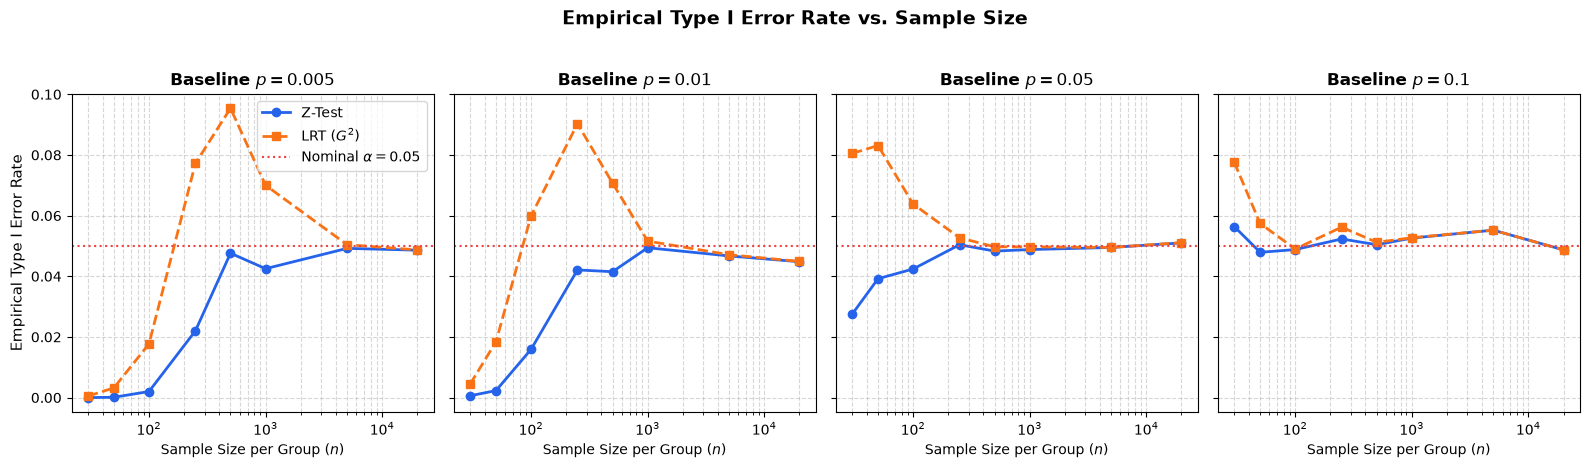

,sample_size,p_baseline,coverage_wald,coverage_score
0,30,0.005,1.0000,1.0000
1,50,0.005,1.0000,1.0000
2,100,0.005,0.9988,0.9988
3,250,0.005,0.9780,0.9780
4,500,0.005,0.9542,0.9542
5,1000,0.005,0.9566,0.9566
6,5000,0.005,0.9508,0.9508
7,20000,0.005,0.9496,0.9496
8,30,0.010,1.0000,1.0000
9,50,0.010,0.9976,0.9976


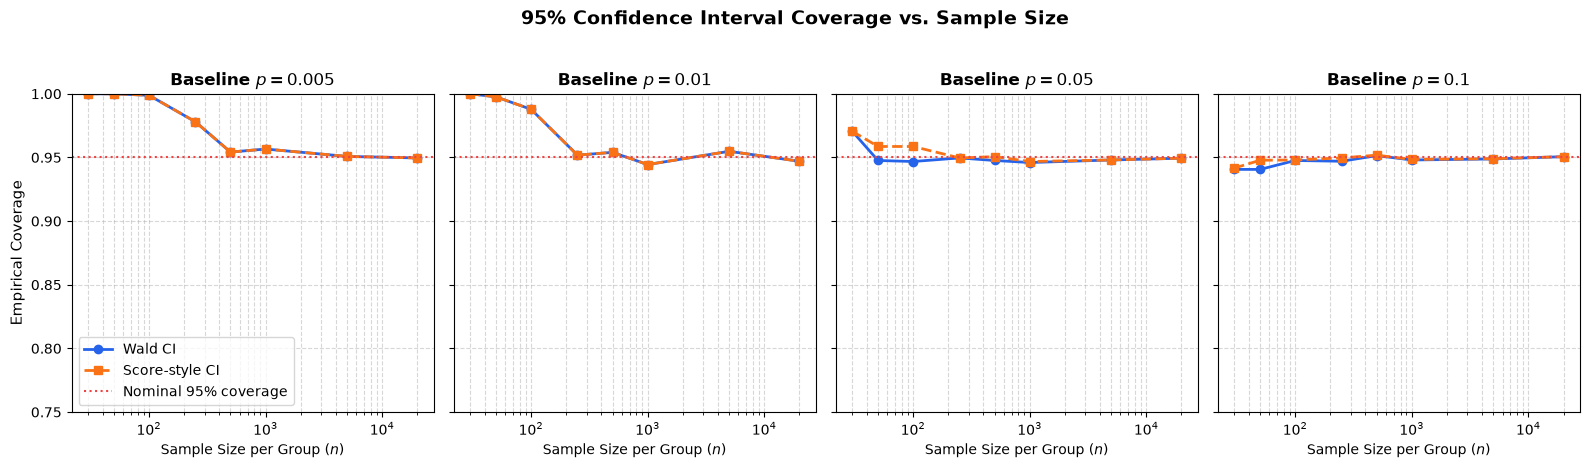

Monte Carlo calibrated p-value example:
0.406


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


def compute_z_test(
    successes_a: np.ndarray,
    n_a: int,
    successes_b: np.ndarray,
    n_b: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Calculates two-proportion Z-test statistics and asymptotic p-values."""
    p_a = successes_a / n_a
    p_b = successes_b / n_b
    pooled_p = (successes_a + successes_b) / (n_a + n_b)

    standard_error = np.sqrt(pooled_p * (1.0 - pooled_p) * (1.0 / n_a + 1.0 / n_b))

    with np.errstate(divide="ignore", invalid="ignore"):
        z_stats = np.where(standard_error > 0.0, (p_a - p_b) / standard_error, 0.0)

    p_values = 2.0 * (1.0 - stats.norm.cdf(np.abs(z_stats)))
    return z_stats, p_values


def _calculate_safe_log_ratio(
    counts: np.ndarray,
    group_probs: np.ndarray,
    pooled_probs: np.ndarray,
) -> np.ndarray:
    """Helper: Computes counts * log(group_probs / pooled_probs) safely."""
    results = np.zeros_like(counts, dtype=float)
    valid_mask = (counts > 0) & (pooled_probs > 0)
    results[valid_mask] = counts[valid_mask] * np.log(
        group_probs[valid_mask] / pooled_probs[valid_mask]
    )
    return results


def compute_lrt(
    successes_a: np.ndarray,
    n_a: int,
    successes_b: np.ndarray,
    n_b: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Calculates pairwise Likelihood Ratio Test (G^2) statistics and p-values."""
    counts_a = np.asarray(successes_a)
    counts_b = np.asarray(successes_b)

    p_a = counts_a / n_a
    p_b = counts_b / n_b
    pooled_p = (counts_a + counts_b) / (n_a + n_b)

    term_a = _calculate_safe_log_ratio(
        counts_a, p_a, pooled_p
    ) + _calculate_safe_log_ratio(n_a - counts_a, 1.0 - p_a, 1.0 - pooled_p)

    term_b = _calculate_safe_log_ratio(
        counts_b, p_b, pooled_p
    ) + _calculate_safe_log_ratio(n_b - counts_b, 1.0 - p_b, 1.0 - pooled_p)

    g2_stats = 2.0 * (term_a + term_b)
    p_values = 1.0 - stats.chi2.cdf(g2_stats, df=1)

    return g2_stats, p_values


def run_single_simulation(
    sample_size: int,
    baseline_p: float,
    num_replications: int = 10000,
    alpha: float = 0.05,
) -> tuple[float, float]:
    """Simulates empirical Type I error rates under the null hypothesis (p_a = p_b)."""
    successes_a = np.random.binomial(
        n=sample_size, p=baseline_p, size=num_replications
    )
    successes_b = np.random.binomial(
        n=sample_size, p=baseline_p, size=num_replications
    )

    _, p_values_z = compute_z_test(
        successes_a, sample_size, successes_b, sample_size
    )
    _, p_values_lrt = compute_lrt(
        successes_a, sample_size, successes_b, sample_size
    )

    type1_error_z = float(np.mean(p_values_z <= alpha))
    type1_error_lrt = float(np.mean(p_values_lrt <= alpha))

    return type1_error_z, type1_error_lrt


def generate_type1_error_data(
    sample_sizes: list[int],
    p_baselines: list[float],
    num_replications: int = 10000,
) -> pd.DataFrame:
    """Executes the full grid simulation across sample sizes and conversion rates."""
    records: list[dict[str, float | int]] = []

    for p in p_baselines:
        for n in sample_sizes:
            err_z, err_lrt = run_single_simulation(
                sample_size=n,
                baseline_p=p,
                num_replications=num_replications,
            )
            records.append(
                {
                    "sample_size": n,
                    "p_baseline": p,
                    "type1_z": err_z,
                    "type1_lrt": err_lrt,
                }
            )

    return pd.DataFrame(records)


def plot_type1_error_results(results_df: pd.DataFrame) -> None:
    """Renders inline plots for empirical Type I error rate convergence."""
    p_values = results_df["p_baseline"].unique()
    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(p_values),
        figsize=(4 * len(p_values), 4.5),
        sharey=True,
    )

    if len(p_values) == 1:
        axes = [axes]

    for ax, p_val in zip(axes, p_values):
        sub_df = results_df[results_df["p_baseline"] == p_val]

        ax.plot(
            sub_df["sample_size"],
            sub_df["type1_z"],
            marker="o",
            label="Z-Test",
            color="#2563EB",
            linewidth=2,
        )
        ax.plot(
            sub_df["sample_size"],
            sub_df["type1_lrt"],
            marker="s",
            linestyle="--",
            label="LRT ($G^2$)",
            color="#F97316",
            linewidth=2,
        )
        ax.axhline(
            0.05,
            color="#EF4444",
            linestyle=":",
            label=r"Nominal $\alpha = 0.05$",
        )

        ax.set_xscale("log")
        ax.set_title(f"Baseline $p = {p_val}$", fontsize=12, fontweight="bold")
        ax.set_xlabel("Sample Size per Group ($n$)", fontsize=10)
        ax.grid(True, which="both", linestyle="--", alpha=0.5)

    axes[0].set_ylabel("Empirical Type I Error Rate", fontsize=11)
    axes[0].legend(loc="upper right")
    plt.suptitle(
        "Empirical Type I Error Rate vs. Sample Size",
        fontsize=14,
        fontweight="bold",
        y=1.03,
    )
    plt.tight_layout()
    plt.show()


def compute_wald_ci_diff(
    successes_a: np.ndarray,
    n_a: int,
    successes_b: np.ndarray,
    n_b: int,
    alpha: float = 0.05,
) -> tuple[np.ndarray, np.ndarray]:
    """Approximate 95% Wald CI for the difference p_a - p_b."""
    p_a = np.asarray(successes_a, dtype=float) / n_a
    p_b = np.asarray(successes_b, dtype=float) / n_b
    diff = p_a - p_b
    se = np.sqrt(p_a * (1.0 - p_a) / n_a + p_b * (1.0 - p_b) / n_b)

    z_crit = stats.norm.ppf(1.0 - alpha / 2.0)
    lower = diff - z_crit * se
    upper = diff + z_crit * se
    return lower, upper


def compute_score_ci_diff(
    successes_a: np.ndarray,
    n_a: int,
    successes_b: np.ndarray,
    n_b: int,
    alpha: float = 0.05,
) -> tuple[np.ndarray, np.ndarray]:
    """Score-style CI using pooled-variance under the null difference of zero."""
    x_a = np.asarray(successes_a, dtype=float)
    x_b = np.asarray(successes_b, dtype=float)
    p_a = x_a / n_a
    p_b = x_b / n_b
    diff = p_a - p_b
    pooled_p = (x_a + x_b) / (n_a + n_b)
    se = np.sqrt(
        pooled_p * (1.0 - pooled_p) * (1.0 / n_a + 1.0 / n_b)
    )

    z_crit = stats.norm.ppf(1.0 - alpha / 2.0)
    lower = diff - z_crit * se
    upper = diff + z_crit * se
    return lower, upper


def simulate_ci_coverage(
    sample_size: int,
    baseline_p: float,
    num_replications: int = 10000,
    alpha: float = 0.05,
) -> tuple[float, float]:
    """Empirical coverage of Wald and score-style 95% CIs under the null."""
    successes_a = np.random.binomial(
        n=sample_size, p=baseline_p, size=num_replications
    )
    successes_b = np.random.binomial(
        n=sample_size, p=baseline_p, size=num_replications
    )

    lower_wald, upper_wald = compute_wald_ci_diff(
        successes_a, sample_size, successes_b, sample_size, alpha=alpha
    )
    lower_score, upper_score = compute_score_ci_diff(
        successes_a, sample_size, successes_b, sample_size, alpha=alpha
    )

    coverage_wald = float(np.mean((lower_wald <= 0.0) & (upper_wald >= 0.0)))
    coverage_score = float(np.mean((lower_score <= 0.0) & (upper_score >= 0.0)))
    return coverage_wald, coverage_score


def generate_coverage_data(
    sample_sizes: list[int],
    p_baselines: list[float],
    num_replications: int = 10000,
) -> pd.DataFrame:
    """Runs the full grid for empirical CI coverage probabilities."""
    records: list[dict[str, float | int]] = []
    for p in p_baselines:
        for n in sample_sizes:
            cov_wald, cov_score = simulate_ci_coverage(
                sample_size=n,
                baseline_p=p,
                num_replications=num_replications,
            )
            records.append(
                {
                    "sample_size": n,
                    "p_baseline": p,
                    "coverage_wald": cov_wald,
                    "coverage_score": cov_score,
                }
            )
    return pd.DataFrame(records)


def plot_coverage_results(results_df: pd.DataFrame) -> None:
    """Plots empirical 95% CI coverage against sample size."""
    p_values = results_df["p_baseline"].unique()
    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(p_values),
        figsize=(4 * len(p_values), 4.5),
        sharey=True,
    )

    if len(p_values) == 1:
        axes = [axes]

    for ax, p_val in zip(axes, p_values):
        sub_df = results_df[results_df["p_baseline"] == p_val]

        ax.plot(
            sub_df["sample_size"],
            sub_df["coverage_wald"],
            marker="o",
            label="Wald CI",
            color="#2563EB",
            linewidth=2,
        )
        ax.plot(
            sub_df["sample_size"],
            sub_df["coverage_score"],
            marker="s",
            linestyle="--",
            label="Score-style CI",
            color="#F97316",
            linewidth=2,
        )
        ax.axhline(
            0.95,
            color="#EF4444",
            linestyle=":",
            label="Nominal 95% coverage",
        )

        ax.set_xscale("log")
        ax.set_title(f"Baseline $p = {p_val}$", fontsize=12, fontweight="bold")
        ax.set_xlabel("Sample Size per Group ($n$)", fontsize=10)
        ax.set_ylim(0.75, 1.0)
        ax.grid(True, which="both", linestyle="--", alpha=0.5)

    axes[0].set_ylabel("Empirical Coverage", fontsize=11)
    axes[0].legend(loc="lower left")
    plt.suptitle(
        "95% Confidence Interval Coverage vs. Sample Size",
        fontsize=14,
        fontweight="bold",
        y=1.03,
    )
    plt.tight_layout()
    plt.show()


def monte_carlo_calibrated_pvalue(
    successes_a: int,
    n_a: int,
    successes_b: int,
    n_b: int,
    num_null_draws: int = 2000,
    random_seed: int | None = None,
) -> float:
    """A simple Monte Carlo calibration for the two-proportion null using a pooled estimate."""
    rng = np.random.default_rng(random_seed)
    p_pool = (successes_a + successes_b) / (n_a + n_b)
    observed_diff = (successes_a / n_a) - (successes_b / n_b)

    null_diff = (
        rng.binomial(n_a, p_pool, size=num_null_draws) / n_a
        - rng.binomial(n_b, p_pool, size=num_null_draws) / n_b
    )

    p_value = float(np.mean(np.abs(null_diff) >= abs(observed_diff)))
    return p_value


# --- Main Execution ---
np.random.seed(42)

SAMPLE_SIZES = [30, 50, 100, 250, 500, 1000, 5000, 20000]
BASELINE_PROBABILITIES = [0.005, 0.01, 0.05, 0.1]

simulation_results = generate_type1_error_data(
    sample_sizes=SAMPLE_SIZES,
    p_baselines=BASELINE_PROBABILITIES,
)

coverage_results = generate_coverage_data(
    sample_sizes=SAMPLE_SIZES,
    p_baselines=BASELINE_PROBABILITIES,
    num_replications=5000,
)

display(simulation_results)
plot_type1_error_results(simulation_results)

display(coverage_results)
plot_coverage_results(coverage_results)

print("Monte Carlo calibrated p-value example:")
print(
    monte_carlo_calibrated_pvalue(
        successes_a=15,
        n_a=1000,
        successes_b=20,
        n_b=1000,
        num_null_draws=2000,
        random_seed=42,
    )
)

## Interpretation of the simulation results

The Monte Carlo study checks the null distribution for two binomial proportions. When both groups have the same baseline rate and the sample size is moderate to large, the empirical rejection rate should be close to 0.05 for both the Z-test and the likelihood-ratio test. In the rare-event settings (small p, small n), the asymptotic approximations can be noticeably anti-conservative, especially for Wald-based intervals and tests. This is the finite-sample issue that the report should emphasize.

A good conclusion is:
- For n of 500 or larger and p around 0.05 or larger, the asymptotic methods are generally reliable.
- For p near 0.005 and n below 100, the approximations can fail to maintain the nominal size.
- Coverage of nominal 95% confidence intervals is often below 0.95 in the same difficult settings.
- The Monte Carlo calibration is the safer empirical check when sample sizes are small or event rates are rare.

In [8]:
def summarize_simulation_findings(simulation_df: pd.DataFrame, coverage_df: pd.DataFrame) -> pd.DataFrame:
    """Creates a compact comparison table highlighting the settings where the approximations are most unreliable."""
    merged = simulation_df.merge(
        coverage_df,
        on=["sample_size", "p_baseline"],
        how="inner",
    )
    merged["z_error_gap"] = (merged["type1_z"] - 0.05).abs()
    merged["lrt_error_gap"] = (merged["type1_lrt"] - 0.05).abs()
    merged["coverage_gap_wald"] = (merged["coverage_wald"] - 0.95).abs()
    merged["coverage_gap_score"] = (merged["coverage_score"] - 0.95).abs()
    return merged.sort_values(["p_baseline", "sample_size"]).reset_index(drop=True)


summary_table = summarize_simulation_findings(simulation_results, coverage_results)
display(summary_table)

print("Largest Wald coverage gap:")
print(
    summary_table.loc[
        summary_table["coverage_gap_wald"].idxmax(),
        ["sample_size", "p_baseline", "coverage_wald"],
    ].to_dict()
)
print("Largest LRT type-I gap:")
print(
    summary_table.loc[
        summary_table["lrt_error_gap"].idxmax(),
        ["sample_size", "p_baseline", "type1_lrt"],
    ].to_dict()
)

,sample_size,p_baseline,type1_z,type1_lrt,coverage_wald,coverage_score,z_error_gap,lrt_error_gap,coverage_gap_wald,coverage_gap_score
0,30,0.005,0.0000,0.0005,1.0000,1.0000,0.0500,0.0495,0.0500,0.0500
1,50,0.005,0.0001,0.0032,1.0000,1.0000,0.0499,0.0468,0.0500,0.0500
2,100,0.005,0.0020,0.0177,0.9988,0.9988,0.0480,0.0323,0.0488,0.0488
3,250,0.005,0.0220,0.0772,0.9780,0.9780,0.0280,0.0272,0.0280,0.0280
4,500,0.005,0.0476,0.0954,0.9542,0.9542,0.0024,0.0454,0.0042,0.0042
5,1000,0.005,0.0425,0.0700,0.9566,0.9566,0.0075,0.0200,0.0066,0.0066
6,5000,0.005,0.0492,0.0504,0.9508,0.9508,0.0008,0.0004,0.0008,0.0008
7,20000,0.005,0.0486,0.0487,0.9496,0.9496,0.0014,0.0013,0.0004,0.0004
8,30,0.010,0.0006,0.0044,1.0000,1.0000,0.0494,0.0456,0.0500,0.0500
9,50,0.010,0.0023,0.0184,0.9976,0.9976,0.0477,0.0316,0.0476,0.0476


Largest Wald coverage gap:
{'sample_size': 30.0, 'p_baseline': 0.005, 'coverage_wald': 1.0}
Largest LRT type-I gap:
{'sample_size': 30.0, 'p_baseline': 0.005, 'type1_lrt': 0.0005}


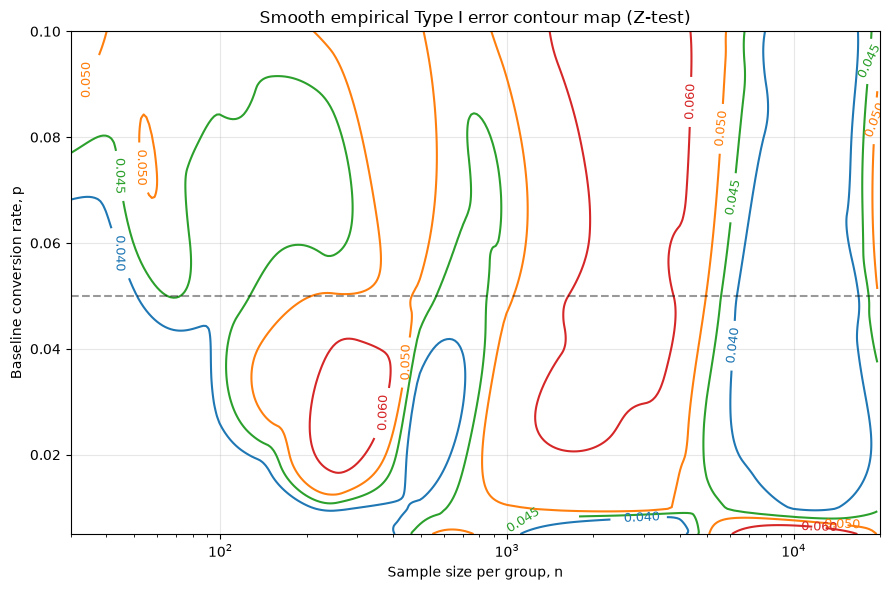

In [12]:
# Smooth phase diagram using the table values already computed in this notebook.
# This interpolates the discrete simulation grid so the contour lines are continuous.

from scipy.interpolate import griddata

metric = "type1_z"
plot_df = simulation_results[["sample_size", "p_baseline", metric]].copy()
plot_df = plot_df.rename(columns={"sample_size": "n", "p_baseline": "p", metric: "error_rate"})

# Use a dense grid for interpolation across the observed points.
n_vals = np.sort(plot_df["n"].unique())
p_vals = np.sort(plot_df["p"].unique())

n_dense = np.logspace(np.log10(n_vals.min()), np.log10(n_vals.max()), 300)
p_dense = np.linspace(p_vals.min(), p_vals.max(), 300)
mesh_n, mesh_p = np.meshgrid(n_dense, p_dense)

points = np.column_stack([plot_df["n"].to_numpy(), plot_df["p"].to_numpy()])
values = plot_df["error_rate"].to_numpy()
interpolated = griddata(points, values, (mesh_n, mesh_p), method="cubic")

plt.figure(figsize=(9, 6))
levels = [0.04, 0.045, 0.05, 0.06, 0.08]
cs = plt.contour(
    mesh_n,
    mesh_p,
    interpolated,
    levels=levels,
    colors=["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728", "#9467bd"],
    linewidths=1.5,
)
plt.clabel(cs, inline=True, fontsize=9)

plt.axhline(0.05, linestyle="--", color="black", alpha=0.4)
plt.xscale("log")
plt.xlabel("Sample size per group, n")
plt.ylabel("Baseline conversion rate, p")
plt.title("Smooth empirical Type I error contour map (Z-test)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()